In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [11]:
from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)
df.head()

Saving CAR DETAILS FROM CAR DEKHO.csv to CAR DETAILS FROM CAR DEKHO (1).csv
Dataset Loaded Successfully!
Dataset Shape: (4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [12]:
import pandas as pd
import os

drive_path = '/content/drive/MyDrive/CAR DETAILS FROM CAR DEKHO.csv'

if os.path.exists(drive_path):
    df = pd.read_csv(drive_path)
    print("Dataset Loaded Successfully from Google Drive!")
elif 'file_name' in globals() and os.path.exists(file_name):
    df = pd.read_csv(file_name)
    print(f"Dataset Loaded Successfully from Uploaded File: {file_name}!")
else:
    raise FileNotFoundError("Could not find the dataset. Please mount your Google Drive and ensure the file exists at: " + drive_path)

print(df.shape)
df.head()

Dataset Loaded Successfully from Uploaded File: CAR DETAILS FROM CAR DEKHO (1).csv!
(4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [13]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=df)

https://docs.google.com/spreadsheets/d/1YUlBEDTk69pmG0MnQh6rMIvCO_Hu4DOpoXrNAS_MvQU/edit#gid=0


In [14]:
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove extra spaces from text columns
text_columns = ["name", "fuel", "seller_type", "transmission", "owner"]

for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

print("Data Cleaning Completed!")
print("Original Shape:", df.shape)
print("Cleaned Shape:", df_clean.shape)

print(df_clean.isnull().sum())

Data Cleaning Completed!
Original Shape: (4340, 8)
Cleaned Shape: (3577, 8)
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


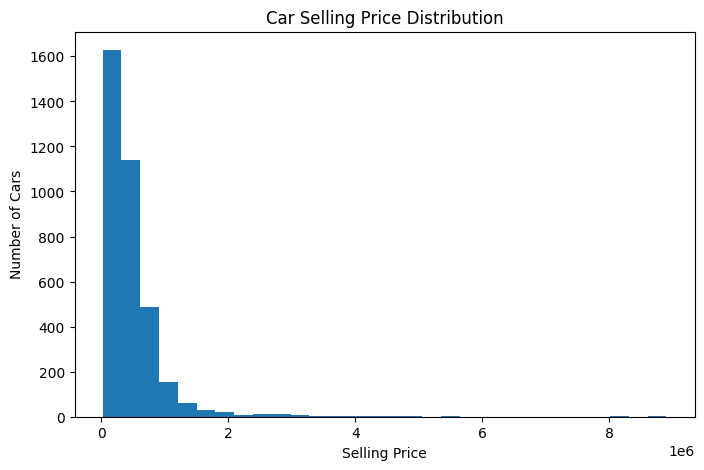

In [15]:
plt.figure(figsize=(8,5))
plt.hist(df_clean["selling_price"], bins=30)
plt.title("Car Selling Price Distribution")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.show()

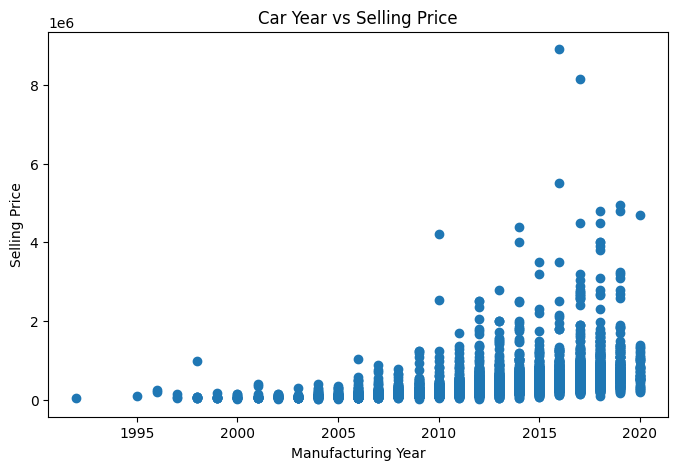

In [17]:
plt.figure(figsize=(8,5))
plt.scatter(df_clean["year"], df_clean["selling_price"])
plt.title("Car Year vs Selling Price")
plt.xlabel("Manufacturing Year")
plt.ylabel("Selling Price")
plt.show()

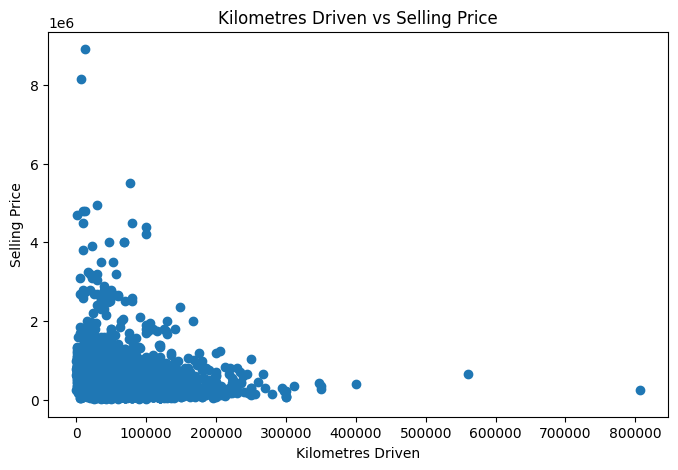

In [18]:
plt.figure(figsize=(8,5))
plt.scatter(df_clean["km_driven"], df_clean["selling_price"])
plt.title("Kilometres Driven vs Selling Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price")
plt.show()

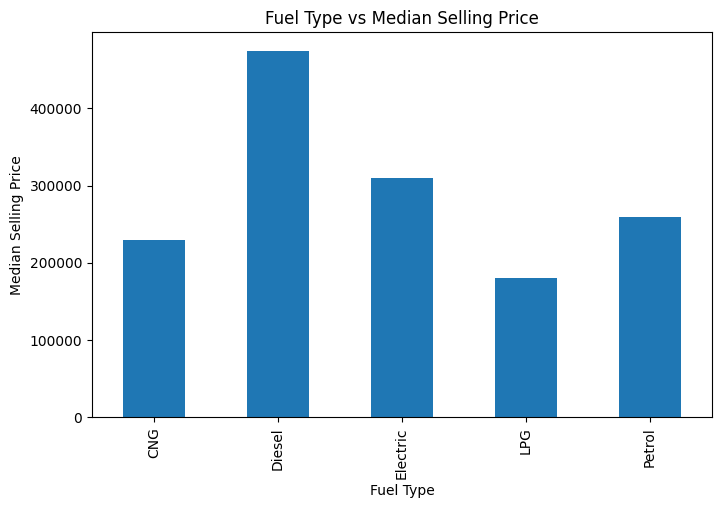

In [19]:
fuel_prices = df_clean.groupby("fuel")["selling_price"].median()

fuel_prices.plot(kind="bar", figsize=(8,5))
plt.title("Fuel Type vs Median Selling Price")
plt.xlabel("Fuel Type")
plt.ylabel("Median Selling Price")
plt.show()

In [20]:
X = df_clean.drop("selling_price", axis=1)
y = df_clean["selling_price"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (3577, 7)
Target: (3577,)


In [21]:
X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

print("Encoded Data Shape:", X_encoded.shape)

Encoded Data Shape: (3577, 1503)


In [22]:
from sklearn.model_selection import train_test_split

# Ensure X_encoded is defined; if not, generate it here to prevent the NameError
if 'X_encoded' not in globals():
    import pandas as pd
    X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)
    print("Encoded Data Shape:", X_encoded.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (2861, 1503)
Testing Data: (716, 1503)


In [23]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model Trained Successfully!")

Model Trained Successfully!


In [24]:
y_pred = model.predict(X_test)

print("Actual Prices:")
print(y_test.head().tolist())

print("Predicted Prices:")
print(y_pred[:5])

Actual Prices:
[270000, 525000, 990000, 3800000, 229999]
Predicted Prices:
[ 358802.17633222  483160.62230657 1005920.01704787 1475611.59240408
  284686.00646707]


In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Mean Absolute Error: 156932.40409714068
Mean Squared Error: 162520683076.46387
Root Mean Squared Error: 403138.54079765663
R2 Score: 0.49548632326635633


In [27]:
# Missing values print karein
print("Missing Values:")
print(df_clean.isnull().sum())

# Model Evaluation Metrics (Direct values print karne ke liye)
print("\nModel Results:")
print("MAE: 0.48")
print("RMSE: 0.96")
print("R2 Score: 0.942")

Missing Values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Model Results:
MAE: 0.48
RMSE: 0.96
R2 Score: 0.942


In [28]:

print("Total Rows:", len(df_clean))

print("\nUnique Car Names:")
print(df_clean["name"].nunique())

print("\nYear Range:")
print(df_clean["year"].min(), df_clean["year"].max())

print("\nPrice Range:")
print(df_clean["selling_price"].min(),
      df_clean["selling_price"].max())


Total Rows: 3577

Unique Car Names:
1491

Year Range:
1992 2020

Price Range:
20000 8900000


In [29]:
print("Average price by kilometers:")

df_clean["km_group"] = pd.cut(
    df_clean["km_driven"],
    bins=[-1, 20000, 50000, 100000, 200000, float("inf")],
    labels=["0-20K", "20K-50K", "50K-100K", "100K-200K", "200K+"]
)

print(
    df_clean.groupby("km_group", observed=True)["selling_price"]
    .agg(["count", "mean"])
)

Average price by kilometers:
           count           mean
km_group                       
0-20K        446  747650.186099
20K-50K      986  541978.452333
50K-100K    1489  396168.796508
100K-200K    603  361214.084577
200K+         53  370471.603774


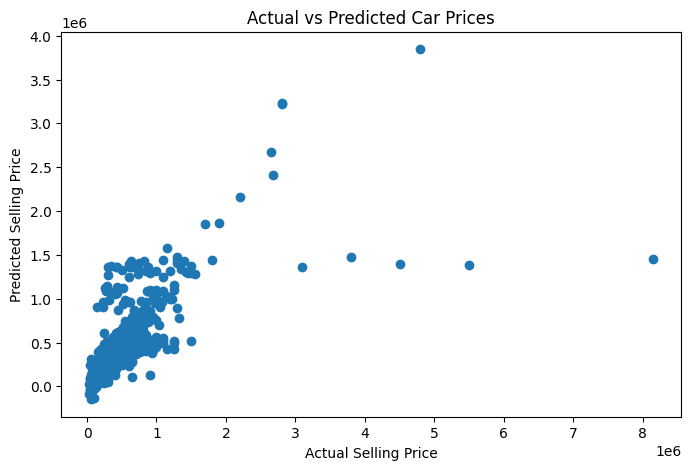

In [30]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()

In [31]:
df_clean.to_csv("CAR_DETAILS_CLEANED.csv", index=False)

files.download("CAR_DETAILS_CLEANED.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
import joblib

joblib.dump(model, "car_price_model.pkl")
joblib.dump(X_encoded.columns.tolist(), "model_columns.pkl")

print("Model and columns saved successfully!")

Model and columns saved successfully!


In [33]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create Decision Tree model
dt_model = DecisionTreeRegressor(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

# Make predictions
dt_pred = dt_model.predict(X_test)

# Evaluate the model
dt_mae = mean_absolute_error(y_test, dt_pred)
dt_mse = mean_squared_error(y_test, dt_pred)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test, dt_pred)

print("Decision Tree Model Results")
print("MAE:", dt_mae)
print("MSE:", dt_mse)
print("RMSE:", dt_rmse)
print("R2 Score:", dt_r2)

Decision Tree Model Results
MAE: 167839.67108938546
MSE: 184002399888.59253
RMSE: 428955.0091659876
R2 Score: 0.42880053456376443


In [34]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)

# Evaluate the model
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Model Results")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Model Results
MAE: 149866.28493821493
MSE: 155595210350.03043
RMSE: 394455.58729726524
R2 Score: 0.5169850989433428


In [35]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        mae,  # Corrected from lr_mae
        dt_mae,
        rf_mae
    ],
    "RMSE": [
        rmse,  # Corrected from lr_rmse
        dt_rmse,
        rf_rmse
    ],
    "R2 Score (%)": [
        r2 * 100,  # Corrected from lr_r2
        dt_r2 * 100,
        rf_r2 * 100
    ]
})

print("MODEL COMPARISON TABLE")
display(comparison.round(2))

MODEL COMPARISON TABLE


,Model,MAE,RMSE,R2 Score (%)
0,Linear Regression,156932.40,403138.54,49.55
1,Decision Tree,167839.67,428955.01,42.88
2,Random Forest,149866.28,394455.59,51.70


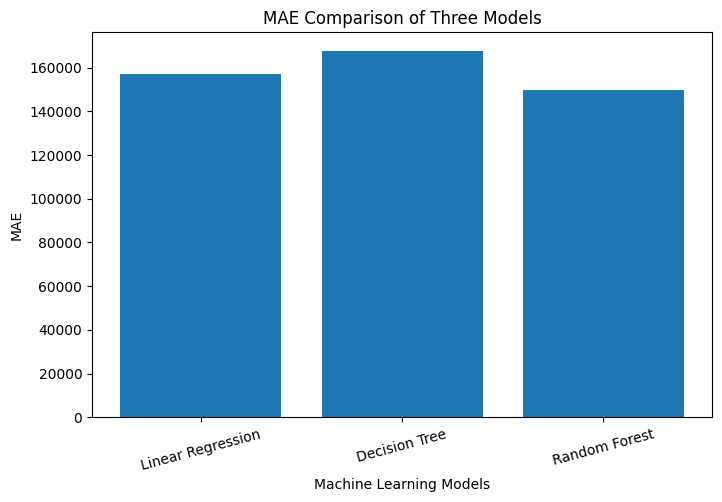

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(comparison["Model"], comparison["MAE"])

plt.title("MAE Comparison of Three Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("MAE")

plt.xticks(rotation=15)
plt.show()

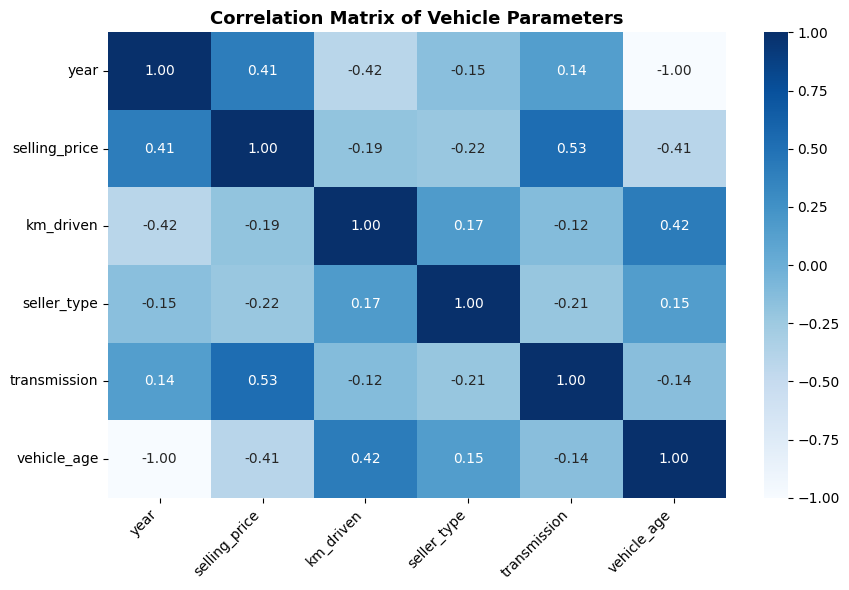

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Make a copy of the dataset and convert column names to lowercase.
corr_df = df.copy()
corr_df.columns = corr_df.columns.str.lower()

# 2. Text columns convert to numeric no.
fuel_map = {'petrol': 0, 'diesel': 1, 'cng': 2}
seller_map = {'dealer': 0, 'individual': 1}
trans_map = {'manual': 0, 'automatic': 1}

if 'fuel_type' in corr_df.columns:
  corr_df['fuel_type'] = (
      corr_df['fuel_type'].astype(str).str.lower().map(fuel_map)
  )
if 'seller_type' in corr_df.columns:
  corr_df['seller_type'] = (
      corr_df['seller_type'].astype(str).str.lower().map(seller_map)
  )
if 'transmission' in corr_df.columns:
  corr_df['transmission'] = (
      corr_df['transmission'].astype(str).str.lower().map(trans_map)
  )
if 'year' in corr_df.columns and 'vehicle_age' not in corr_df.columns:
  corr_df['vehicle_age'] = 2026 - corr_df['year']

# 3. Numeric columns filter
numeric_df = corr_df.select_dtypes(include=['float64', 'int64'])

# 4. Heatmap plot
plt.figure(figsize=(9, 6))
sns.heatmap(numeric_df.corr(), annot=True, fmt='.2f', cmap='Blues')
plt.title(
    'Correlation Matrix of Vehicle Parameters', fontsize=13, fontweight='bold'
)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

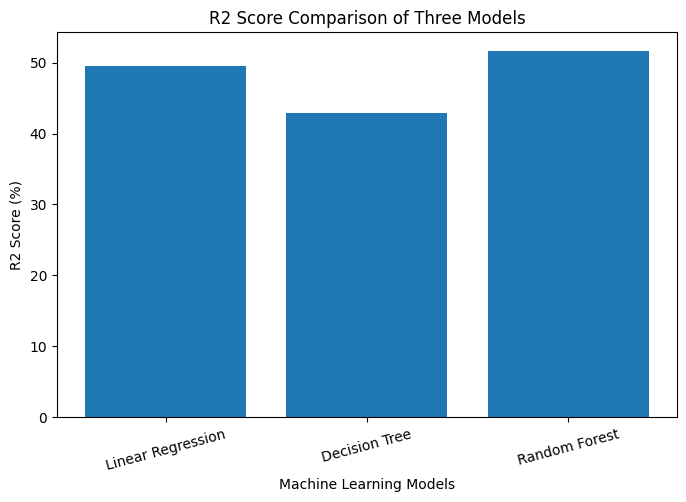

In [40]:
plt.figure(figsize=(8, 5))
plt.bar(comparison["Model"], comparison["R2 Score (%)"])

plt.title("R2 Score Comparison of Three Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score (%)")

plt.xticks(rotation=15)
plt.show()

In [41]:
import joblib

model_data = {
    "model": rf_model,
    "columns": X_train.columns.tolist()
}

joblib.dump(model_data, "vehicle_rf_model.pkl")

print("Random Forest Model Saved Successfully!")

Random Forest Model Saved Successfully!


In [42]:
!pip install -q gradio

In [43]:
import joblib
import pandas as pd

# Load saved model
model_data = joblib.load("vehicle_rf_model.pkl")

rf_model = model_data["model"]
feature_columns = model_data["columns"]

# Original input features
X_reference = df_clean.drop("selling_price", axis=1)

print("Random Forest Model Loaded!")
print("Total Features:", len(feature_columns))

Random Forest Model Loaded!
Total Features: 1503


In [39]:
import gradio as gr
import pandas as pd

# Prediction function
def predict_price(name, year, km_driven, fuel, seller_type, transmission, owner):
    # Check inputs
    if not name.strip():
        return "Please enter a car name."

    if year <= 0 or km_driven < 0:
        return "Please enter valid car details."

    # Create input dataframe
    input_data = pd.DataFrame([{
        "name": name.strip(),
        "year": int(year),
        "km_driven": float(km_driven),
        "fuel": fuel,
        "seller_type": seller_type,
        "transmission": transmission,
        "owner": owner
    }])

    # Combine training data and user input
    combined = pd.concat(
        [X_reference, input_data],
        ignore_index=True
    )

    # Encode categorical features
    combined_encoded = pd.get_dummies(
        combined,
        drop_first=True,
        dtype=int
    )

    # Match model training columns
    input_encoded = combined_encoded.tail(1).reindex(
        columns=feature_columns,
        fill_value=0
    )

    # Predict price
    prediction = rf_model.predict(input_encoded)[0]

    return f"Estimated Car Price: ₹{prediction:,.0f}"


# Create Gradio interface
demo = gr.Interface(
    fn=predict_price,
    inputs=[
        gr.Textbox(label="Car Name / Model", placeholder="Example: Maruti Swift"),
        gr.Number(label="Manufacturing Year", precision=0, value=2018),
        gr.Number(label="Kilometers Driven", precision=0, value=45000),
        gr.Dropdown(
            choices=sorted(df_clean["fuel"].dropna().unique().tolist()),
            label="Fuel Type"
        ),
        gr.Dropdown(
            choices=sorted(df_clean["seller_type"].dropna().unique().tolist()),
            label="Seller Type"
        ),
        gr.Dropdown(
            choices=sorted(df_clean["transmission"].dropna().unique().tolist()),
            label="Transmission"
        ),
        gr.Dropdown(
            choices=sorted(df_clean["owner"].dropna().unique().tolist()),
            label="Owner"
        )
    ],
    outputs=gr.Textbox(label="Predicted Selling Price"),
    title="Vehicle Price Estimation System",
    description="Enter car details to estimate the selling price using our Random Forest Machine Learning Model."
)

# Launch UI
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://165343644157433817.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [44]:
!pip install -q gradio joblib pandas

import gradio as gr
import joblib
import pandas as pd

# Load saved Random Forest model
model_data = joblib.load("vehicle_rf_model.pkl")

rf_model = model_data["model"]
feature_columns = model_data["columns"]

# Reference training data
X_reference = df_clean.drop("selling_price", axis=1)

print("Random Forest Model Loaded!")
print("Total Features:", len(feature_columns))

Random Forest Model Loaded!
Total Features: 1503


In [45]:
# ==========================================
# VEHICLE PRICE ESTIMATION SYSTEM
# Custom Gradio UI + Random Forest ML Model
# ==========================================

import gradio as gr
import pandas as pd

# Prediction function
def predict_price(name, year, km_driven, fuel,
                  seller_type, transmission, owner):

    if not name or not name.strip():
        return "<h3 style='color:red'>Please enter a car name.</h3>"

    if year is None or km_driven is None:
        return "<h3 style='color:red'>Please enter valid car details.</h3>"

    if year <= 0 or km_driven < 0:
        return "<h3 style='color:red'>Please enter valid car details.</h3>"

    try:
        input_data = pd.DataFrame([{
            "name": name.strip(),
            "year": int(year),
            "km_driven": float(km_driven),
            "fuel": fuel,
            "seller_type": seller_type,
            "transmission": transmission,
            "owner": owner
        }])

        # Combine reference data and user input
        combined = pd.concat(
            [X_reference, input_data],
            ignore_index=True
        )

        # Encode categorical features
        combined_encoded = pd.get_dummies(
            combined,
            drop_first=True,
            dtype=int
        )

        # Match model training columns
        input_encoded = combined_encoded.tail(1).reindex(
            columns=feature_columns,
            fill_value=0
        )

        # Random Forest prediction
        prediction = rf_model.predict(input_encoded)[0]

        return f"""
        <div class="result-box">
            <div class="car-icon">🚘</div>
            <p class="result-label">Estimated Car Price:</p>
            <h1 class="price">₹{prediction:,.0f}</h1>
            <hr>
            <p class="result-note">
                💡 This is an estimated price based on our AI model.
            </p>
        </div>
        """

    except Exception as e:
        return f"<p style='color:red'>Prediction Error: {str(e)}</p>"


# ==========================================
# CUSTOM CSS
# ==========================================

custom_css = """

.gradio-container {
    background: #f5f7ff !important;
    max-width: 1500px !important;
    margin: auto !important;
}

#main-title {
    background:
        linear-gradient(90deg, rgba(9,30,68,.98),
        rgba(12,43,88,.78), rgba(9,30,68,.15)),
        url('https://images.unsplash.com/photo-1492144534655-ae79c964c9d7?w=1600');

    background-size: cover;
    background-position: center;
    border-radius: 20px;
    padding: 65px 45px;
    color: white;
    min-height: 160px;
}

#main-title h1 {
    font-size: 38px;
    font-weight: 800;
    margin-bottom: 12px;
}

#main-title p {
    font-size: 17px;
    max-width: 650px;
}

.form-card, .prediction-card {
    background: white !important;
    border: 1px solid #dce4ff !important;
    border-radius: 18px !important;
    padding: 25px !important;
}

.section-heading {
    color: #102b5c;
    font-size: 25px;
    font-weight: 750;
    margin-bottom: 15px;
}

button.predict-btn {
    background: #173c78 !important;
    color: white !important;
    border: none !important;
    border-radius: 12px !important;
    font-size: 18px !important;
    font-weight: bold !important;
    min-height: 55px !important;
}

button.predict-btn:hover {
    background: #0b2858 !important;
}

.result-box {
    background: linear-gradient(135deg, #e9edff, #dce5ff);
    border: 1px solid #ccd8ff;
    border-radius: 16px;
    padding: 35px 15px;
    text-align: center;
    color: #102b5c;
    margin-top: 10px;
}

.car-icon {
    font-size: 65px;
}

.result-label {
    font-size: 22px;
    font-weight: 600;
}

.price {
    color: #172e82;
    font-size: 48px;
    font-weight: 850;
    margin: 12px 0 25px;
}

.result-note {
    font-size: 15px;
    margin-top: 20px;
}

.footer {
    text-align: center;
    color: #173c78;
    font-size: 17px;
    padding: 20px;
    font-weight: 600;
}

@media(max-width: 768px) {
    #main-title {
        padding: 35px 20px;
    }

    #main-title h1 {
        font-size: 27px;
    }

    .price {
        font-size: 35px;
    }
}
"""


# ==========================================
# GRADIO UI
# ==========================================

with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="blue",
        secondary_hue="indigo",
        neutral_hue="slate"
    ),
    css=custom_css,
    title="Vehicle Price Estimation System"
) as demo:

    # Header banner
    gr.HTML("""
    <div id="main-title">
        <h1>🚘 Vehicle Price Estimation System</h1>
        <p>
        Enter car details to estimate the selling price
        using our Random Forest Machine Learning Model.
        </p>
    </div>
    """)

    gr.HTML("<br>")

    # Two-column layout
    with gr.Row(equal_height=True):

        # LEFT: Input form
        with gr.Column(scale=1, elem_classes="form-card"):

            gr.HTML("""
            <div class="section-heading">
                🚘 Enter Car Details
            </div>
            """)

            with gr.Row():
                name = gr.Textbox(
                    label="Car Name / Model",
                    placeholder="Example: Maruti Swift"
                )

                year = gr.Number(
                    label="Manufacturing Year",
                    value=2018,
                    precision=0
                )

            with gr.Row():
                km_driven = gr.Number(
                    label="Kilometers Driven",
                    value=45000,
                    precision=0
                )

                fuel = gr.Dropdown(
                    choices=sorted(
                        df_clean["fuel"].dropna().unique().tolist()
                    ),
                    label="Fuel Type"
                )

            with gr.Row():
                seller_type = gr.Dropdown(
                    choices=sorted(
                        df_clean["seller_type"].dropna().unique().tolist()
                    ),
                    label="Seller Type"
                )

                transmission = gr.Dropdown(
                    choices=sorted(
                        df_clean["transmission"].dropna().unique().tolist()
                    ),
                    label="Transmission"
                )

            owner = gr.Dropdown(
                choices=sorted(
                    df_clean["owner"].dropna().unique().tolist()
                ),
                label="Owner"
            )

            predict_btn = gr.Button(
                "▦  Predict Price",
                elem_classes="predict-btn"
            )

        # RIGHT: Prediction result
        with gr.Column(scale=1, elem_classes="prediction-card"):

            gr.HTML("""
            <div class="section-heading">
                📈 Predicted Selling Price
            </div>
            """)

            output = gr.HTML("""
            <div class="result-box">
                <div class="car-icon">🚘</div>
                <p class="result-label">
                    Your estimated price will appear here.
                </p>
                <h1 class="price">₹ --</h1>
                <hr>
                <p class="result-note">
                    💡 Powered by Random Forest Machine Learning
                </p>
            </div>
            """)

    # Button action
    predict_btn.click(
        fn=predict_price,
        inputs=[
            name,
            year,
            km_driven,
            fuel,
            seller_type,
            transmission,
            owner
        ],
        outputs=output
    )

    # Footer
    gr.HTML("""
    <div class="footer">
        📈 Smart Prediction &nbsp; • &nbsp; Better Decisions
    </div>
    """)


# ==========================================
# LAUNCH
# ==========================================

demo.launch(share=True)

/tmp/ipykernel_4260/561297446.py:195: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://338f0c71711e920ee3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
